##  Diplomado en Ciencia de Datos

<h1 align = 'center'> Desbalanceo de clases en problemas de clasificación </h1>

En muchos problemas reales (fraude, diagnóstico de enfermedades raras, fallas de equipos, deserción, detección de intrusiones) la clase que más nos interesa es **muy poco frecuente**. Cuando una clase representa el 1 % o menos de los datos, los algoritmos de aprendizaje, las métricas habituales (como la *accuracy*) y hasta los procedimientos de validación pueden engañarnos: un modelo que siempre responde "no hay fraude" obtiene 99 % de exactitud y no sirve para nada.

En este cuaderno veremos:

1. Qué es el desbalanceo y cómo **medirlo y evaluarlo** correctamente.
2. Las **técnicas** para tratarlo: a nivel de datos (remuestreo), a nivel de algoritmo (pesos y costos), a nivel de decisión (umbral y calibración) y ensambles especializados.
3. **Qué tan susceptible es cada modelo** de las notas anteriores (regresión logística, SVM, KNN, árboles, Random Forest y Gradient Boosting) y **cómo puede corregirlo** cada uno.
4. **Simulaciones Monte Carlo** para comprobar empíricamente lo anterior.
5. **Ejercicios** (con sus soluciones en `Ejercicios/Soluciones/`).

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [1. Conceptos y métricas](#conceptos)
- [2. Técnicas para tratar el desbalanceo](#tecnicas)
- [3. Susceptibilidad de cada modelo](#susceptibilidad)
- [4. Simulaciones](#simulaciones)
- [5. Ejercicios](#ejercicios)

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn imbalanced-learn joblib

/home/juanf/Projects/Material-Ciencia-de-Datos/.venv/bin/python3: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from sklearn.datasets import make_classification, load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, TunedThresholdClassifierCV)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, roc_auc_score, average_precision_score,
                             brier_score_loss, confusion_matrix)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.combine import SMOTETomek
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier, BalancedBaggingClassifier

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25})

<a id="conceptos"></a>
<h2 style="color: #007ACC;">1. Conceptos y métricas</h2>

Sea $\pi = P(Y=1)$ la prevalencia de la clase minoritaria (positiva). El **índice de desbalanceo** (*imbalance ratio*, IR) es

$$IR = \frac{n_{\text{mayoritaria}}}{n_{\text{minoritaria}}} = \frac{1-\pi}{\pi}$$

Un IR de 1:1 es un problema balanceado; 1:10 es un desbalanceo moderado; 1:100 o más es severo. Hay que distinguir dos cosas que suelen confundirse:

- **La proporción** (IR): afecta cómo la función de pérdida reparte su atención entre clases.
- **El número absoluto de ejemplos minoritarios**: con 10 positivos no hay técnica que reconstruya la frontera, aunque el IR sea 1:1 en otro conjunto. Más adelante lo comprobaremos por simulación.

<h3 style="color: #007ACC;">Por qué falla la accuracy</h3>

Con prevalencia $\pi$, un clasificador constante que siempre predice la clase mayoritaria tiene $\text{accuracy}=1-\pi$ y recall nulo. Veámoslo.

In [3]:
def generar_datos(n, prev, sep=1.0, semilla=0):
    """Datos sintéticos de 10 variables (4 informativas, 2 redundantes, 2 clusters por clase)."""
    return make_classification(n_samples=n, n_features=10, n_informative=4, n_redundant=2,
                               n_clusters_per_class=2, weights=[1 - prev, prev], flip_y=0,
                               class_sep=sep, random_state=semilla)

X, y = generar_datos(20000, prev=0.01, semilla=1)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.5, stratify=y, random_state=0)
print(f'Prevalencia: {y.mean():.2%}  |  IR = 1:{(1 - y.mean()) / y.mean():.0f}  |  positivos en entrenamiento: {y_tr.sum()}')

dummy = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
for nombre, m in [('Siempre "negativo"', dummy), ('Regresión logística', logit)]:
    p = m.predict(X_te)
    print(f'{nombre:22s} accuracy={accuracy_score(y_te, p):.3f}  recall={recall_score(y_te, p):.3f}')

Prevalencia: 1.00%  |  IR = 1:99  |  positivos en entrenamiento: 100
Siempre "negativo"     accuracy=0.990  recall=0.000
Regresión logística    accuracy=0.990  recall=0.000


La *accuracy* del clasificador trivial (99 %) es prácticamente igual a la de un modelo real: **no discrimina**. Necesitamos métricas que miren la clase minoritaria. Con la matriz de confusión (TP, FP, FN, TN; ver `05_Matriz_Confusión.ipynb`):

| Métrica | Definición | Comentario |
|---|---|---|
| Recall (sensibilidad) | $\frac{TP}{TP+FN}$ | Qué fracción de los positivos reales detectamos. No depende de la prevalencia. |
| Precisión | $\frac{TP}{TP+FP}$ | **Sí depende de la prevalencia**: con $\pi$ pequeño, pocos FP bastan para hundirla. |
| $F_1$ | $\frac{2PR}{P+R}$ | Media armónica de precisión y recall; ignora los TN. |
| Accuracy balanceada | $\frac{1}{2}\left(\text{recall}+\text{especificidad}\right)$ | Promedio del recall por clase. |
| MCC | $\frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$ | Correlación entre predicción y realidad; informativa aun con desbalanceo fuerte. |
| ROC-AUC | Área bajo la curva TPR vs FPR | Insensible a la prevalencia, lo que puede ocultar un mal desempeño práctico. |
| PR-AUC (*average precision*) | Área bajo la curva precisión-recall | Su línea base es $\pi$ (no 0.5); **la métrica de ranking recomendada** con desbalanceo. |

**Idea clave:** la ROC-AUC puede ser alta (0.95) mientras la precisión es 5 %, porque el FPR se calcula sobre una clase negativa enorme. La PR-AUC lo hace visible.

In [4]:
def evaluar(modelo, X_te, y_te):
    """Métricas con el umbral por defecto (clasificación) y métricas de ranking (puntajes)."""
    pred = modelo.predict(X_te)
    puntaje = modelo.predict_proba(X_te)[:, 1] if hasattr(modelo, 'predict_proba') else modelo.decision_function(X_te)
    return {'accuracy': accuracy_score(y_te, pred),
            'recall': recall_score(y_te, pred),
            'precision': precision_score(y_te, pred, zero_division=0),
            'f1': f1_score(y_te, pred, zero_division=0),
            'bal_acc': balanced_accuracy_score(y_te, pred),
            'mcc': matthews_corrcoef(y_te, pred),
            'roc_auc': roc_auc_score(y_te, puntaje),
            'pr_auc': average_precision_score(y_te, puntaje)}

pd.DataFrame({'Siempre negativo': evaluar(DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr), X_te, y_te),
              'Reg. logística': evaluar(logit, X_te, y_te)}).T.round(3)

,accuracy,recall,precision,f1,bal_acc,mcc,roc_auc,pr_auc
Siempre negativo,0.99,0.0,0.0,0.0,0.5,0.000,0.500,0.010
Reg. logística,0.99,0.0,0.0,0.0,0.5,-0.001,0.871,0.054


Observa que la ROC-AUC de la regresión logística es considerablemente más alta que su PR-AUC, y que el *recall* con el umbral de 0.5 es bajo: el modelo **sí ordena** razonablemente los casos (buena ROC-AUC), pero casi nunca cruza el umbral de 0.5 porque la probabilidad que aprende está dominada por la prevalencia. Este diagnóstico (ordena bien, decide mal) motiva el ajuste de umbral más adelante.

<h3 style="color: #007ACC;">Reglas de evaluación con desbalanceo</h3>

1. Usa **particiones estratificadas** (`stratify=y`, `StratifiedKFold`) para que cada pliegue conserve la proporción de clases.
2. Reporta **varias métricas** (recall, precisión, $F_1$/MCC y PR-AUC), no solo accuracy.
3. **Nunca remuestrees el conjunto de prueba** ni los pliegues de validación: el desbalanceo real es parte de lo que quieres medir.
4. El remuestreo se hace **dentro** de cada pliegue de entrenamiento (con `imblearn.pipeline.Pipeline`), nunca antes de dividir (fuga de datos).
5. Con pocos positivos, repite la validación (`RepeatedStratifiedKFold`): las métricas tienen una varianza enorme.

<a id="tecnicas"></a>
<h2 style="color: #007ACC;">2. Técnicas para tratar el desbalanceo</h2>

Las técnicas se pueden agrupar según *dónde* intervienen:

| Nivel | Técnica | Idea |
|---|---|---|
| **Datos** | Sub-muestreo aleatorio | Descartar ejemplos de la clase mayoritaria. |
| | Sobre-muestreo aleatorio | Duplicar ejemplos de la clase minoritaria. |
| | SMOTE y variantes | Crear ejemplos sintéticos interpolando entre vecinos minoritarios. |
| | Tomek links, ENN | Limpiar la frontera eliminando pares de clases opuestas muy cercanos. |
| **Algoritmo** | Pesos de clase / de muestra | Penalizar más los errores en la clase minoritaria (aprendizaje sensible al costo). |
| **Decisión** | Ajuste de umbral | Mover el punto de corte de la probabilidad o del puntaje. |
| | Corrección de probabilidades | Re-calibrar tras haber alterado la prevalencia. |
| **Ensambles** | *Balanced* Random Forest, EasyEnsemble, Balanced Bagging | Cada modelo base ve una muestra balanceada; se promedian muchos. |

<h3 style="color: #007ACC;">2.1 Remuestreo</h3>

Primero visualicemos en 2D cómo cada técnica cambia el conjunto de entrenamiento.

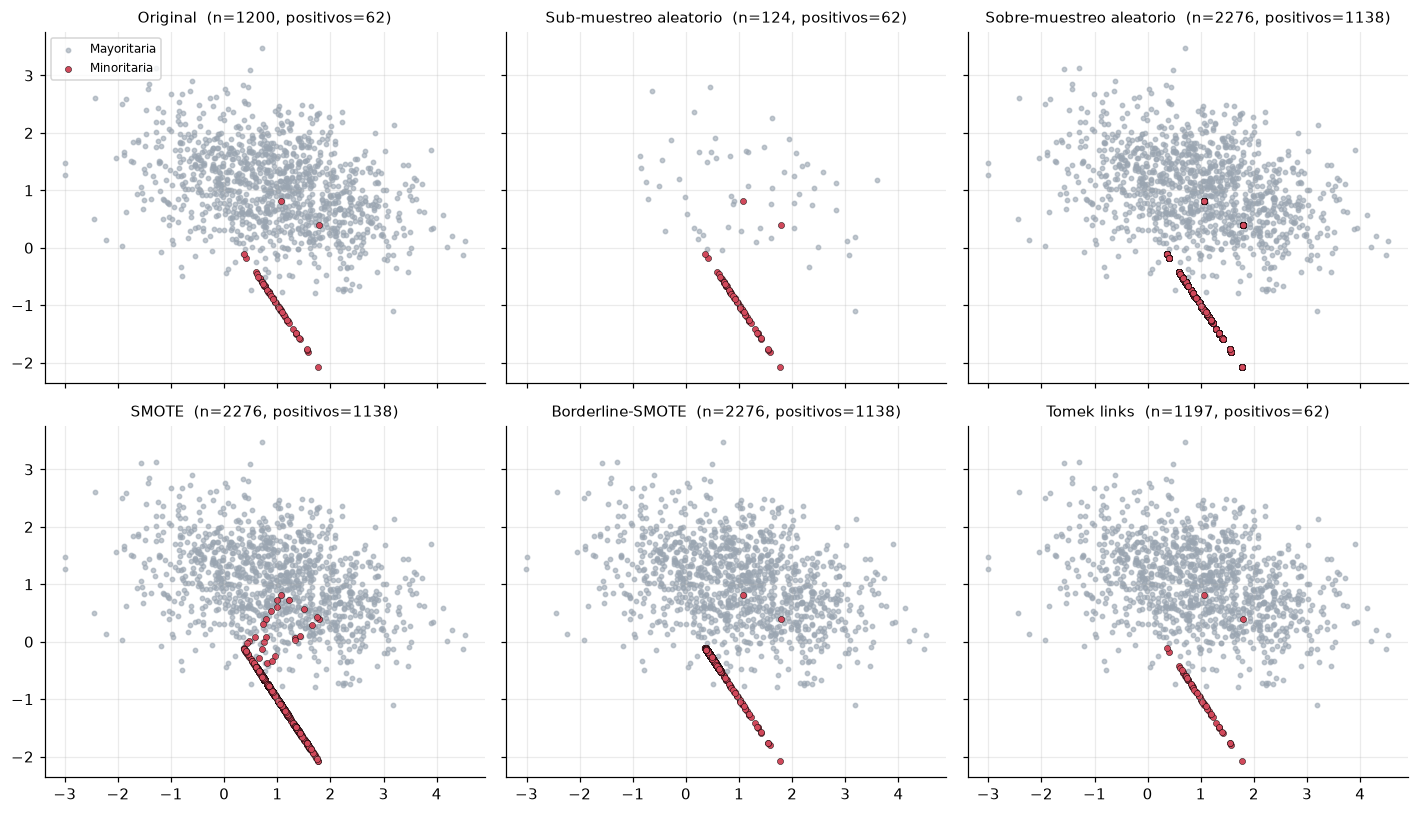

In [5]:
X2, y2 = make_classification(n_samples=1200, n_features=2, n_informative=2, n_redundant=0,
                             n_clusters_per_class=1, weights=[.95, .05], class_sep=1.0, random_state=3)

tecnicas = {'Original': None,
            'Sub-muestreo aleatorio': RandomUnderSampler(random_state=0),
            'Sobre-muestreo aleatorio': RandomOverSampler(random_state=0),
            'SMOTE': SMOTE(random_state=0),
            'Borderline-SMOTE': BorderlineSMOTE(random_state=0),
            'Tomek links': TomekLinks()}

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True, sharey=True)
for ax, (nombre, t) in zip(axes.ravel(), tecnicas.items()):
    Xr, yr = (X2, y2) if t is None else t.fit_resample(X2, y2)
    ax.scatter(*Xr[yr == 0].T, s=8, c='#9aa5b1', alpha=.6, label='Mayoritaria')
    ax.scatter(*Xr[yr == 1].T, s=16, c='#d1495b', edgecolor='k', linewidth=.3, label='Minoritaria')
    ax.set_title(f'{nombre}  (n={len(yr)}, positivos={yr.sum()})', fontsize=10)
axes[0, 0].legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

**Sub-muestreo aleatorio.** Rápido y reduce el costo de entrenamiento, pero tira información de la clase mayoritaria; aumenta la varianza.

**Sobre-muestreo aleatorio.** No pierde información, pero duplica puntos exactos: los modelos de alta capacidad (árboles profundos, KNN con $k=1$) los memorizan y sobreajustan.

**SMOTE** (*Synthetic Minority Over-sampling Technique*). Para cada ejemplo minoritario $x_i$ se escoge al azar uno de sus $k$ vecinos minoritarios $x_{nn}$ y se genera

$$x_{\text{nuevo}} = x_i + \lambda\,(x_{nn}-x_i),\qquad \lambda\sim U(0,1)$$

Rellena la región convexa de la clase minoritaria en lugar de duplicar puntos. Limitaciones: asume que interpolar entre vecinos produce puntos válidos (problemático con variables categóricas o ruido), puede generar ejemplos en zonas de solapamiento y sufre en alta dimensión porque las distancias pierden significado. **Borderline-SMOTE** solo genera cerca de la frontera; **SMOTE + Tomek** o **SMOTE + ENN** limpian el solapamiento después.

**Tomek links.** Un par $(x_i,x_j)$ de clases distintas es un *Tomek link* si cada uno es el vecino más cercano del otro. Eliminar el miembro mayoritario despeja la frontera, pero **no balancea** por sí solo.

<div style="border-left: 4px solid #d1495b; padding: 6px 12px; background: rgba(209,73,91,.08);">
<b>Fuga de datos.</b> El remuestreo debe hacerse únicamente con los datos de entrenamiento de cada pliegue. Si aplicas SMOTE antes de dividir o de hacer validación cruzada, los puntos sintéticos (interpolaciones de puntos que quedaron en validación) filtran información y las métricas salen infladas. Usa <code>imblearn.pipeline.Pipeline</code>, que aplica el remuestreo solo en <code>fit</code> y nunca en <code>predict</code>.
</div>

In [6]:
# Forma correcta: el remuestreo vive dentro del pipeline y solo actúa sobre los datos de entrenamiento
pipe = ImbPipeline([('escala', StandardScaler()),
                    ('smote', SMOTE(random_state=0)),
                    ('modelo', LogisticRegression(max_iter=1000))])

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring='average_precision').mean().round(3)

np.float64(0.058)

<h3 style="color: #007ACC;">2.2 Aprendizaje sensible al costo (pesos de clase)</h3>

En vez de modificar los datos, modificamos la **función de pérdida**. Asignando un peso $w_k$ a cada clase, la pérdida empírica es

$$\mathcal{L}(\theta)=\sum_{i=1}^{n} w_{y_i}\,\ell\big(y_i,f_\theta(x_i)\big)$$

La opción `class_weight='balanced'` de scikit-learn usa $w_k = \dfrac{n}{K\,n_k}$ (con $K$ clases), de modo que cada clase aporta el mismo peso total. Es equivalente, en esperanza, a sobre-muestrear la minoritaria, pero **sin duplicar datos** ni cambiar el tamaño del conjunto. Todos los modelos que admiten `class_weight` o `sample_weight` pueden usarlo; KNN es la excepción (lo veremos).

Si conoces los costos reales de cada error ($c_{FN}$ y $c_{FP}$), mejor que `balanced` es fijar $w_1/w_0 = c_{FN}/c_{FP}$.

<h3 style="color: #007ACC;">2.3 Ajuste del umbral de decisión</h3>

Casi todos los clasificadores producen un puntaje o probabilidad $\hat p(x)$ y clasifican como positivo si $\hat p(x) > t$ con $t=0.5$. Ese 0.5 solo es óptimo si los errores cuestan lo mismo y las probabilidades están bien calibradas. Con costos $c_{FP}$ y $c_{FN}$, el umbral que minimiza el costo esperado es

$$t^* = \frac{c_{FP}}{c_{FP}+c_{FN}}$$

Si $c_{FN}=20\,c_{FP}$, entonces $t^*\approx 0.048$. En la práctica, se elige $t$ en validación para maximizar la métrica de negocio ($F_1$, costo, recall con precisión mínima...). Scikit-learn trae `TunedThresholdClassifierCV` para esto, con validación cruzada interna.

**Ventaja:** no toca los datos ni el entrenamiento, y es válida para cualquier modelo que produzca un puntaje. **Desventaja:** no cambia el *ranking* (la PR-AUC es idéntica); si el modelo aprendió mal la frontera, mover el corte no lo arregla.

<h3 style="color: #007ACC;">2.4 Ensambles para datos desbalanceados</h3>

- **`BalancedRandomForestClassifier`**: cada árbol se entrena con una muestra bootstrap *balanceada* (sub-muestreo de la mayoritaria).
- **`BalancedBaggingClassifier`**: *bagging* de cualquier estimador, con remuestreo balanceado en cada bolsa.
- **`EasyEnsembleClassifier`**: *bagging* de AdaBoost, donde cada AdaBoost se entrena con un sub-muestreo distinto. Al ser muchos modelos, el sub-muestreo ya no descarta información "globalmente".

Estos métodos combinan la baja pérdida de información del ensamble con la ventaja del sub-muestreo (muestras pequeñas = entrenamiento rápido).

<h3 style="color: #007ACC;">2.5 Comparación de técnicas en un caso</h3>

Probamos todas las técnicas sobre un mismo problema (prevalencia del 2 %), con el mismo modelo base, y evaluamos en un conjunto de prueba con la prevalencia real.

In [7]:
def muestrear_escenario(semilla, n_pos_tr, n_neg_tr, prev_te, n_te=20000, sep=1.0):
    """Crea train/test a partir de un 'pool' balanceado con las mismas distribuciones por clase.
    Permite fijar por separado el nº de positivos y negativos de entrenamiento (para separar IR de tamaño)."""
    X, y = make_classification(n_samples=80000, n_features=10, n_informative=4, n_redundant=2,
                               n_clusters_per_class=2, weights=[.5, .5], flip_y=0, class_sep=sep,
                               random_state=semilla)
    rng = np.random.default_rng(semilla)
    pos = rng.permutation(np.where(y == 1)[0]); neg = rng.permutation(np.where(y == 0)[0])
    n_pos_te = max(int(round(n_te * prev_te)), 100); n_neg_te = n_te - n_pos_te
    tr = rng.permutation(np.concatenate([pos[:n_pos_tr], neg[:n_neg_tr]]))
    te = np.concatenate([pos[-n_pos_te:], neg[-n_neg_te:]])
    return X[tr], y[tr], X[te], y[te]

X_tr, y_tr, X_te, y_te = muestrear_escenario(semilla=0, n_pos_tr=100, n_neg_tr=4900, prev_te=.02)
print(f'Entrenamiento: {len(y_tr)} filas, {y_tr.sum()} positivos ({y_tr.mean():.1%}).  Prueba: {len(y_te)} filas, {y_te.sum()} positivos')

Entrenamiento: 5000 filas, 100 positivos (2.0%).  Prueba: 20000 filas, 400 positivos


In [8]:
def lr(**kw):
    return LogisticRegression(max_iter=1000, **kw)

candidatos = {
    'Sin corrección':           ImbPipeline([('e', StandardScaler()), ('m', lr())]),
    'class_weight=balanced':    ImbPipeline([('e', StandardScaler()), ('m', lr(class_weight='balanced'))]),
    'Sub-muestreo aleatorio':   ImbPipeline([('e', StandardScaler()), ('r', RandomUnderSampler(random_state=0)), ('m', lr())]),
    'Sobre-muestreo aleatorio': ImbPipeline([('e', StandardScaler()), ('r', RandomOverSampler(random_state=0)), ('m', lr())]),
    'SMOTE':                    ImbPipeline([('e', StandardScaler()), ('r', SMOTE(random_state=0)), ('m', lr())]),
    'SMOTE + Tomek':            ImbPipeline([('e', StandardScaler()), ('r', SMOTETomek(random_state=0)), ('m', lr())]),
    'Umbral óptimo (F1)':       TunedThresholdClassifierCV(ImbPipeline([('e', StandardScaler()), ('m', lr())]),
                                                           scoring='f1', cv=5),
}
res = {n: evaluar(m.fit(X_tr, y_tr), X_te, y_te) for n, m in candidatos.items()}
pd.DataFrame(res).T[['recall', 'precision', 'f1', 'bal_acc', 'mcc', 'roc_auc', 'pr_auc']].round(3)

,recall,precision,f1,bal_acc,mcc,roc_auc,pr_auc
Sin corrección,0.000,0.000,0.000,0.500,0.000,0.756,0.044
class_weight=balanced,0.745,0.044,0.084,0.708,0.123,0.759,0.039
Sub-muestreo aleatorio,0.780,0.044,0.084,0.718,0.128,0.756,0.038
Sobre-muestreo aleatorio,0.738,0.045,0.084,0.707,0.123,0.758,0.039
SMOTE,0.720,0.044,0.082,0.699,0.119,0.758,0.040
SMOTE + Tomek,0.720,0.044,0.082,0.699,0.119,0.758,0.040
Umbral óptimo (F1),0.520,0.049,0.089,0.657,0.107,0.756,0.044


Lectura de la tabla (los valores exactos cambian con la semilla, la tendencia no):

- Sin corrección, el modelo **no predice ningún positivo** (recall 0) aunque su ROC-AUC sea 0.76.
- Las técnicas que **cambian el peso efectivo de la clase minoritaria** (pesos, remuestreo) llevan el *recall* a ≈0.7-0.8, pero la precisión se queda en ≈4 %: es un intercambio, no una mejora gratuita. El $F_1$ y el MCC quedan casi iguales entre todas las variantes.
- La **ROC-AUC es prácticamente idéntica** y la PR-AUC incluso baja un poco con las técnicas de balanceo: el ranking de los casos es casi el mismo; lo que cambia es *dónde* cortamos. En un modelo lineal, pesar o remuestrear equivale en gran medida a mover el umbral.
- El **ajuste del umbral** logra el mejor $F_1$ (y mejor precisión) sin tocar los datos.

Estas conclusiones son específicas del modelo lineal; en modelos con más capacidad (árboles, KNN, boosting) las técnicas sí cambian el ranking porque modifican la frontera aprendida, como veremos.

In [9]:
# Ensambles diseñados para desbalanceo
ensambles = {
    'Random Forest':               RandomForestClassifier(300, min_samples_leaf=3, n_jobs=-1, random_state=0),
    'Random Forest (balanced_subsample)': RandomForestClassifier(300, min_samples_leaf=3, class_weight='balanced_subsample', n_jobs=-1, random_state=0),
    'Balanced Random Forest':      BalancedRandomForestClassifier(300, min_samples_leaf=3, n_jobs=-1, random_state=0,
                                                                  sampling_strategy='all', replacement=True, bootstrap=False),
    'Balanced Bagging (árbol)':    BalancedBaggingClassifier(DecisionTreeClassifier(max_depth=8), n_estimators=100, n_jobs=-1, random_state=0),
    'EasyEnsemble':                EasyEnsembleClassifier(n_estimators=30, n_jobs=-1, random_state=0),
}
res = {n: evaluar(m.fit(X_tr, y_tr), X_te, y_te) for n, m in ensambles.items()}
pd.DataFrame(res).T[['recall', 'precision', 'f1', 'bal_acc', 'mcc', 'roc_auc', 'pr_auc']].round(3)

,recall,precision,f1,bal_acc,mcc,roc_auc,pr_auc
Random Forest,0.175,1.000,0.298,0.588,0.415,0.939,0.569
Random Forest (balanced_subsample),0.255,0.879,0.395,0.627,0.469,0.954,0.561
Balanced Random Forest,0.702,0.107,0.186,0.791,0.242,0.901,0.291
Balanced Bagging (árbol),0.725,0.135,0.228,0.815,0.285,0.919,0.350
EasyEnsemble,0.785,0.069,0.127,0.784,0.190,0.837,0.088


Los ensambles balanceados (Balanced RF, Balanced Bagging, EasyEnsemble) logran un recall alto (≈0.7-0.8) pero con precisión baja, y su PR-AUC es **peor** que la del Random Forest común (0.29-0.35 y 0.09 frente a 0.57): al sub-muestrear, cada árbol ve pocos negativos y el ranking global se deteriora. El Random Forest estándar tiene recall bajo y precisión de 1.0 con umbral 0.5, pero es el que mejor ordena; el `balanced_subsample` equilibra algo más ambos errores. Si lo que importa es el ranking, no asumas que el ensamble "balanceado" es mejor: compáralo por PR-AUC y ajusta el umbral.

<h3 style="color: #007ACC;">2.6 Efecto sobre las probabilidades: el problema de la calibración</h3>

Cualquier técnica que altere la prevalencia aparente (pesos balanceados, remuestreo) **distorsiona las probabilidades**: el modelo aprende como si $\pi_s=0.5$ en lugar de $\pi$. Sus salidas dejan de interpretarse como probabilidades reales (son excelentes para *ordenar*, malas para *cuantificar riesgo*). Si el modelo se entrenó con prevalencia aparente $\pi_s$ y la real es $\pi$, se corrige en términos de *odds*:

$$\frac{\hat p_{\text{corr}}}{1-\hat p_{\text{corr}}}=\frac{\hat p_s}{1-\hat p_s}\cdot\frac{\pi/(1-\pi)}{\pi_s/(1-\pi_s)}$$

Para la regresión logística, esto equivale a sumar $\log\frac{\pi/(1-\pi)}{\pi_s/(1-\pi_s)}$ al intercepto: de hecho, el intercepto de una regresión logística es el parámetro que "absorbe" la prevalencia. Veámoslo.

In [10]:
def corregir_prior(p, prev_real, prev_aparente=0.5):
    """Corrige probabilidades de un modelo entrenado con prevalencia aparente distinta a la real."""
    odds = p / (1 - p) * (prev_real / (1 - prev_real)) / (prev_aparente / (1 - prev_aparente))
    return odds / (1 + odds)

pi = y_tr.mean()
m_normal = candidatos['Sin corrección']
m_peso = candidatos['class_weight=balanced']
p_normal = m_normal.predict_proba(X_te)[:, 1]
p_peso = m_peso.predict_proba(X_te)[:, 1]
p_corr = corregir_prior(p_peso, prev_real=pi)

tabla = pd.DataFrame({'Prob. media predicha': [p_normal.mean(), p_peso.mean(), p_corr.mean()],
                      'Prevalencia real (prueba)': y_te.mean(),
                      'Brier': [brier_score_loss(y_te, p) for p in (p_normal, p_peso, p_corr)]},
                     index=['Sin corrección', 'class_weight=balanced', 'balanced + corrección de odds'])
tabla.round(4)

,Prob. media predicha,Prevalencia real (prueba),Brier
Sin corrección,0.0205,0.02,0.0196
class_weight=balanced,0.3839,0.02,0.2101
balanced + corrección de odds,0.0258,0.02,0.0210


Con `class_weight='balanced'` la probabilidad media predicha se dispara muy por encima de la prevalencia real y el *Brier score* empeora; con la corrección de *odds* vuelve a la escala correcta **sin cambiar el ranking**. Conclusión práctica: si necesitas probabilidades (riesgo, precios, decisiones por costo esperado), o no uses balanceo, o corrige/calibra después (`CalibratedClassifierCV`).

<a id="susceptibilidad"></a>
<h2 style="color: #007ACC;">3. Susceptibilidad de cada modelo al desbalanceo</h2>

No todos los modelos sufren igual ni por la misma razón. Para cada uno resumimos el **mecanismo** por el que el desbalanceo les afecta y **qué herramientas propias** tienen para corregirlo.

**Regresión logística** (`04_Regresión_Logística.ipynb`). Maximiza la log-verosimilitud $\sum_i [y_i\log p_i+(1-y_i)\log(1-p_i)]$, dominada por los negativos. Con un modelo bien especificado, el desbalanceo (con suficientes positivos) solo desplaza el **intercepto** en $\log\frac{\pi}{1-\pi}$ y los coeficientes siguen siendo consistentes; por eso el modelo ordena bien pero sus probabilidades son pequeñas y casi nunca superan 0.5. Con **pocos positivos** (regla empírica: menos de ~10-20 eventos por variable) la estimación se vuelve sesgada e inestable. *Correcciones:* `class_weight`, ajuste de umbral, corrección del intercepto, regularización.

**SVM** (`06_SVM.ipynb`). La pérdida *hinge* solo depende de los vectores de soporte, y el margen se calcula con la clase mayoritaria en mayoría: el hiperplano de margen máximo tiende a **acercarse a la minoritaria** y a ignorarla, sobre todo con $C$ pequeño (regularización fuerte). *Correcciones:* `class_weight` multiplica $C$ por clase ($C_k=C\,w_k$), la corrección más natural y efectiva en SVM; también remuestreo. Sus puntajes (`decision_function`) no son probabilidades, así que el umbral se ajusta sobre el puntaje.

**KNN** (`07_KNN.ipynb`). Es el más sensible de forma *local*: la predicción es el voto de los $k$ vecinos, y en una región donde la minoritaria es escasa, casi siempre ganan los negativos; con $k$ grande la minoritaria desaparece por completo. **No tiene un parámetro de peso de clase**; `weights='distance'` ayuda un poco pero no es una corrección de desbalanceo. *Correcciones:* remuestreo (sub-muestreo, SMOTE: ojo, SMOTE es un método de vecinos y funciona bien con KNN), ajuste de umbral sobre la fracción de vecinos positivos, $k$ más pequeño o votos ponderados por clase hechos a mano.

**Árboles de decisión** (`08_árboles_decisión.ipynb`). Los criterios de impureza (Gini, entropía) se calculan sobre proporciones del nodo: un nodo con 98 % de negativos ya es "casi puro", así que el árbol **deja de dividir** antes de aislar a los positivos, y las hojas se etiquetan por mayoría. Un árbol profundo sin restricciones, en cambio, memoriza los positivos y sobreajusta. *Correcciones:* `class_weight` (cambia las proporciones usadas en la impureza y en la etiqueta de la hoja), `min_samples_leaf`/`max_depth` bien elegidos, y usar la proporción de la hoja con umbral ajustado en lugar del voto por mayoría.

**Random Forest** (`09_ensamble.ipynb`). Hereda la fragilidad del árbol, pero el promedio de muchos árboles suaviza el ranking: suele tener muy buena PR-AUC aun sin corrección. Sin embargo, cada *bootstrap* contiene aún menos positivos y las hojas son casi siempre negativas, por lo que las probabilidades quedan subestimadas y el recall con 0.5 es bajo. *Correcciones:* `class_weight='balanced_subsample'`, `BalancedRandomForest`, `max_samples`, umbral.

**Gradient Boosting** (`09_ensamble.ipynb`). Parte del logaritmo de la razón de *odds* de la prevalencia y cada árbol corrige los residuos; los positivos mal clasificados acumulan gradiente, de modo que **tiene un mecanismo implícito de enfoque** hacia los errores. Es de los modelos más robustos al desbalanceo moderado, pero con pocos positivos sobreajusta fácilmente. *Correcciones:* `class_weight`/`sample_weight`, `scale_pos_weight` (XGBoost, LightGBM), parada temprana con PR-AUC, umbral.

<h3 style="color: #007ACC;">Resumen</h3>

| Modelo | Por qué sufre | Corrección nativa | Remuestreo | Umbral |
|---|---|---|---|---|
| Reg. logística | La verosimilitud la dominan los negativos; el intercepto absorbe la prevalencia | `class_weight`, `sample_weight` | Opcional (poca ganancia en ranking) | Muy efectivo |
| SVM | El margen se calcula con la mayoría; frontera sesgada | `class_weight` ($C_k=C w_k$) | Útil | Sobre `decision_function` |
| KNN | Voto local dominado por la mayoría | **Ninguna** | Sobre-muestreo o SMOTE (sube el recall; cuidado con la precisión) | Sobre la fracción de vecinos |
| Árbol | La impureza se satura; hojas por mayoría | `class_weight`, poda | Útil | Sobre la proporción de la hoja |
| Random Forest | Árboles débiles con bootstraps casi sin positivos | `balanced_subsample`, `BalancedRandomForest` | Integrado | Efectivo |
| Gradient Boosting | Sobreajusta los pocos positivos | `class_weight`, `scale_pos_weight` | Opcional | Efectivo |

Estas afirmaciones son hipótesis razonables basadas en cómo funciona cada algoritmo. En la siguiente sección **las comprobamos con simulaciones** (y algunas se matizan).

<a id="simulaciones"></a>
<h2 style="color: #007ACC;">4. Simulaciones</h2>

Diseñamos tres experimentos Monte Carlo con datos sintéticos (`make_classification`): la verdad está controlada, repetimos con varias semillas y reportamos medias y desviaciones.

| Simulación | Pregunta | Qué se varía |
|---|---|---|
| **A** | ¿Cómo se degrada cada modelo cuando baja la prevalencia con **tamaño de entrenamiento fijo**? | Prevalencia (50 % → 1 %), $n$ fijo |
| **B** | ¿Importa más la **proporción** o el **número absoluto** de positivos? | IR de 1:1 a 1:100 con 100 positivos fijos |
| **C** | ¿Qué corrección funciona para cada modelo? | Técnica × modelo con prevalencia del 2 % |

Primero, la infraestructura común: los seis modelos y las correcciones.

In [11]:
NOMBRES = ['Reg. logística', 'SVM lineal', 'SVM RBF', 'KNN (k=5)', 'Árbol (prof. 6)', 'Random Forest', 'Gradient Boosting']
SOPORTA_PESOS = {n: n != 'KNN (k=5)' for n in NOMBRES}

def modelo_base(nombre, pesos=False, semilla=0):
    cw = 'balanced' if pesos else None
    if nombre == 'Reg. logística':   return LogisticRegression(max_iter=1000, class_weight=cw)
    if nombre == 'SVM lineal':       return LinearSVC(class_weight=cw, dual='auto', max_iter=5000)
    if nombre == 'SVM RBF':          return SVC(kernel='rbf', class_weight=cw)
    if nombre == 'KNN (k=5)':        return KNeighborsClassifier(n_neighbors=5)
    if nombre == 'Árbol (prof. 6)':  return DecisionTreeClassifier(max_depth=6, class_weight=cw, random_state=semilla)
    if nombre == 'Random Forest':    return RandomForestClassifier(100, min_samples_leaf=3, n_jobs=1, random_state=semilla,
                                                                   class_weight='balanced_subsample' if pesos else None)
    if nombre == 'Gradient Boosting':return HistGradientBoostingClassifier(class_weight=cw, random_state=semilla)

MUESTREADORES = {'Sub-muestreo': lambda s: RandomUnderSampler(random_state=s),
                 'Sobre-muestreo': lambda s: RandomOverSampler(random_state=s),
                 'SMOTE': lambda s: SMOTE(random_state=s)}

def construir(nombre, remedio='Ninguno', semilla=0):
    """Pipeline: escalado -> (remuestreo) -> modelo, con la corrección pedida."""
    pasos = [('escala', StandardScaler())]
    if remedio in MUESTREADORES:
        pasos.append(('remuestreo', MUESTREADORES[remedio](semilla)))
    pasos.append(('modelo', modelo_base(nombre, pesos=(remedio == 'Pesos de clase'), semilla=semilla)))
    pipe = ImbPipeline(pasos)
    if remedio == 'Umbral (F1)':
        return TunedThresholdClassifierCV(pipe, scoring='f1', cv=3)
    return pipe

In [12]:
def simular(tarea):
    """Una réplica: genera datos, entrena y evalúa. Devuelve un diccionario con la configuración y las métricas."""
    cfg, semilla = tarea
    X_tr, y_tr, X_te, y_te = muestrear_escenario(semilla, cfg['n_pos'], cfg['n_neg'], cfg['prev_te'], sep=cfg.get('sep', 1.0))
    m = construir(cfg['modelo'], cfg.get('remedio', 'Ninguno'), semilla).fit(X_tr, y_tr)
    return {**cfg, 'semilla': semilla, **evaluar(m, X_te, y_te)}

def correr(configs, reps):
    tareas = [(c, s) for c in configs for s in range(reps)]
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(simular)(t) for t in tareas))

COLORES = dict(zip(NOMBRES, ['#1f77b4', '#17becf', '#9467bd', '#d62728', '#ff7f0e', '#2ca02c', '#8c564b']))
ESTILOS = dict(zip(NOMBRES, ['-', '--', '-', '-', '-', '-', '--']))

def graficar(df, x, metricas, titulos=None, logx=False, xlabel=None):
    fig, axes = plt.subplots(1, len(metricas), figsize=(5.2 * len(metricas), 4.3))
    for ax, met in zip(np.atleast_1d(axes), metricas):
        for n in NOMBRES:
            g = df[df.modelo == n].groupby(x)[met].agg(['mean', 'std']).reset_index()
            if g.empty: continue
            ax.errorbar(g[x], g['mean'], yerr=g['std'] / np.sqrt(df.semilla.nunique()), color=COLORES[n], ls=ESTILOS[n],
                        marker='o', ms=4, capsize=2, label=n)
        if logx: ax.set_xscale('log')
        ax.set_xlabel(xlabel or x); ax.set_title(met if not titulos else titulos[met]); ax.set_ylim(-.02, 1.02)
    np.atleast_1d(axes)[-1].legend(fontsize=8, loc='center left', bbox_to_anchor=(1.02, .5))
    plt.tight_layout(); plt.show()

<h3 style="color: #007ACC;">Simulación A. Degradación al bajar la prevalencia (n de entrenamiento fijo)</h3>

Entrenamos con 4 000 filas y la prevalencia baja de 50 % a 1 % (de 2 000 a solo 40 positivos). El conjunto de prueba (20 000 filas) tiene la misma prevalencia que el de entrenamiento. Medimos todo **sin ninguna corrección** y con el umbral estándar: así vemos la susceptibilidad *intrínseca* de cada modelo. Usamos 8 réplicas (semillas) por configuración.

In [13]:
N_TR = 4000
PREVS = [.5, .2, .1, .05, .02, .01]
cfgA = [dict(modelo=n, prev=p, n_pos=int(round(N_TR * p)), n_neg=N_TR - int(round(N_TR * p)), prev_te=p)
        for n in NOMBRES for p in PREVS]
dfA = correr(cfgA, reps=8)
dfA.groupby(['modelo', 'prev'])[['recall', 'pr_auc']].mean().round(3).head(3)

recall  pr_auc
modelo            prev                
Gradient Boosting 0.01   0.279   0.510
                  0.02   0.452   0.680
                  0.05   0.646   0.833

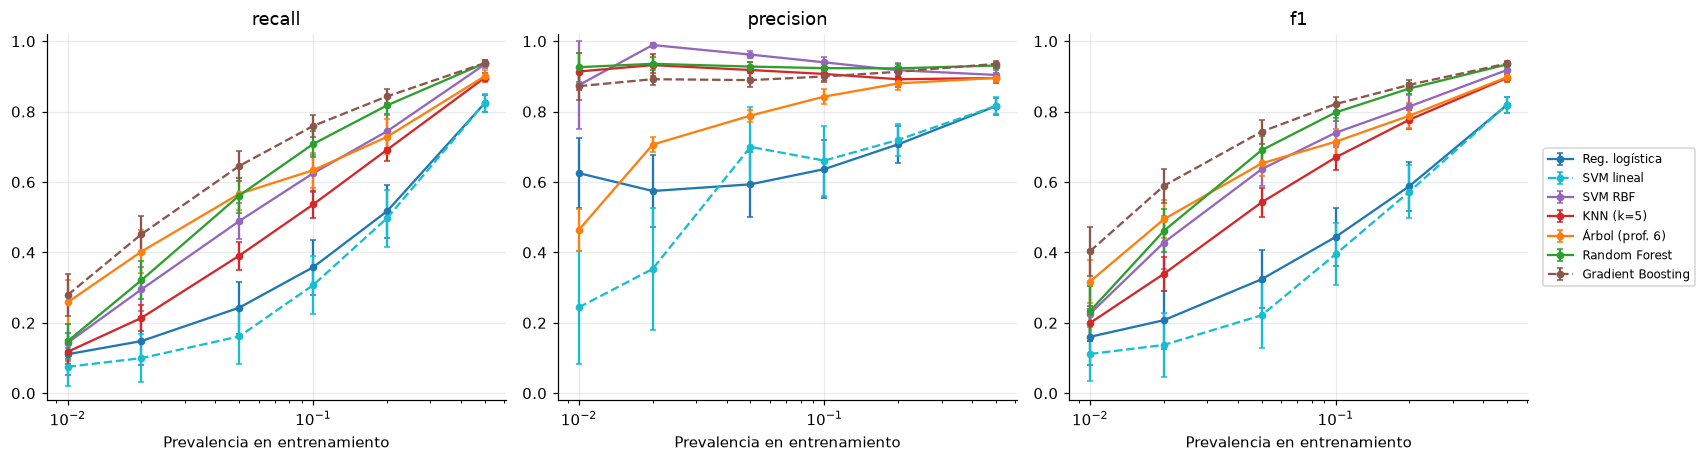

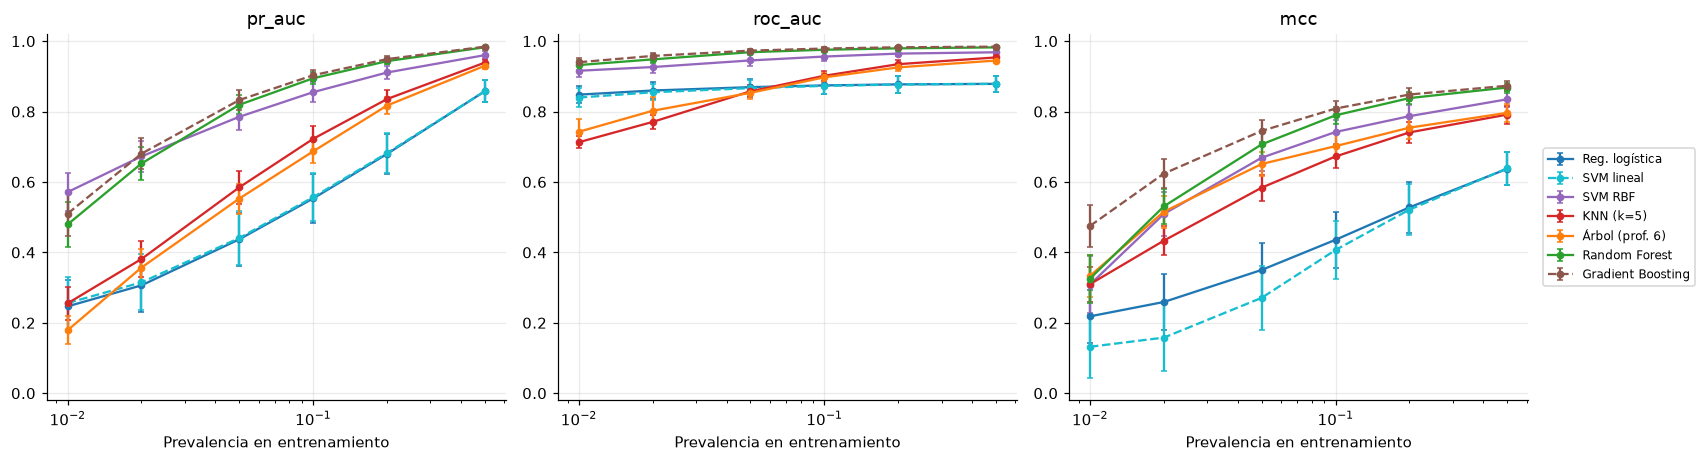

In [14]:
graficar(dfA, 'prev', ['recall', 'precision', 'f1', 'pr_auc', 'roc_auc', 'mcc'][:3], logx=True, xlabel='Prevalencia en entrenamiento')
graficar(dfA, 'prev', ['pr_auc', 'roc_auc', 'mcc'], logx=True, xlabel='Prevalencia en entrenamiento')

In [15]:
# Tabla resumen a prevalencia 1%
dfA[dfA.prev == .01].groupby('modelo')[['recall', 'precision', 'f1', 'mcc', 'roc_auc', 'pr_auc']].mean().loc[NOMBRES].round(3)

,recall,precision,f1,mcc,roc_auc,pr_auc
modelo,,,,,,
Reg. logística,0.111,0.625,0.160,0.218,0.848,0.247
SVM lineal,0.075,0.244,0.111,0.132,0.840,0.256
SVM RBF,0.143,0.875,0.226,0.309,0.916,0.571
KNN (k=5),0.118,0.914,0.199,0.310,0.713,0.255
Árbol (prof. 6),0.258,0.464,0.317,0.333,0.742,0.179
Random Forest,0.148,0.926,0.233,0.325,0.932,0.479
Gradient Boosting,0.279,0.872,0.403,0.475,0.940,0.510


**Lectura (resultados de esta ejecución; con otras semillas varían los decimales, no las tendencias):**

- **Accuracy y ROC-AUC engañan.** La ROC-AUC casi no se mueve cuando baja la prevalencia (gráfico central), mientras que la PR-AUC y el MCC caen con fuerza. Un modelo puede "ordenar bien" (ROC-AUC 0.85-0.94 al 1 %) y aun así tener una PR-AUC baja.
- **Los modelos lineales (regresión logística y SVM lineal) son los más afectados** en esta simulación, y se comportan casi idénticos entre sí (misma familia de frontera, pérdidas parecidas). Su PR-AUC cae de ≈0.86 (50 %) a ≈0.25 (1 %). Cuidado: parte de esa debilidad no es del desbalanceo sino de la **capacidad**: la frontera real tiene varios clusters por clase y un hiperplano no la representa; el desbalanceo agrava esa limitación porque deja pocos positivos para compensarla.
- **Gradient Boosting, Random Forest y SVM RBF son los más robustos en ranking** (PR-AUC ≈0.5-0.57 al 1 %). Gradient Boosting es además el mejor en MCC y $F_1$ sin ninguna corrección.
- **El recall con umbral 0.5 colapsa en todos los modelos** (a 1 %: 0.08-0.28), aun en los que ordenan bien. En los modelos de bajo recall la precisión es alta: el problema es que "casi nunca se atreven" a predecir la clase positiva, no que se equivoquen mucho cuando lo hacen. Esto se arregla moviendo el umbral o reponderando.
- **KNN y el árbol** se ubican en medio: PR-AUC mediocre, con alta varianza entre réplicas; el árbol es el que más se acerca a decidir "positivo" (mayor recall) a costa de precisión.

<h3 style="color: #007ACC;">Simulación B. ¿Proporción o número de positivos?</h3>

Ahora fijamos **100 positivos de entrenamiento** y aumentamos la cantidad de negativos (IR de 1:1 a 1:100). El conjunto de entrenamiento crece (de 200 a 10 100 filas), así que cada modelo ve siempre la misma información sobre la clase minoritaria. Si el problema fuese solo "el desbalanceo", los modelos se degradarían igual que en A. Si es "faltan positivos", casi no se degradarían (o incluso mejorarían, porque ganan más información sobre la región negativa).

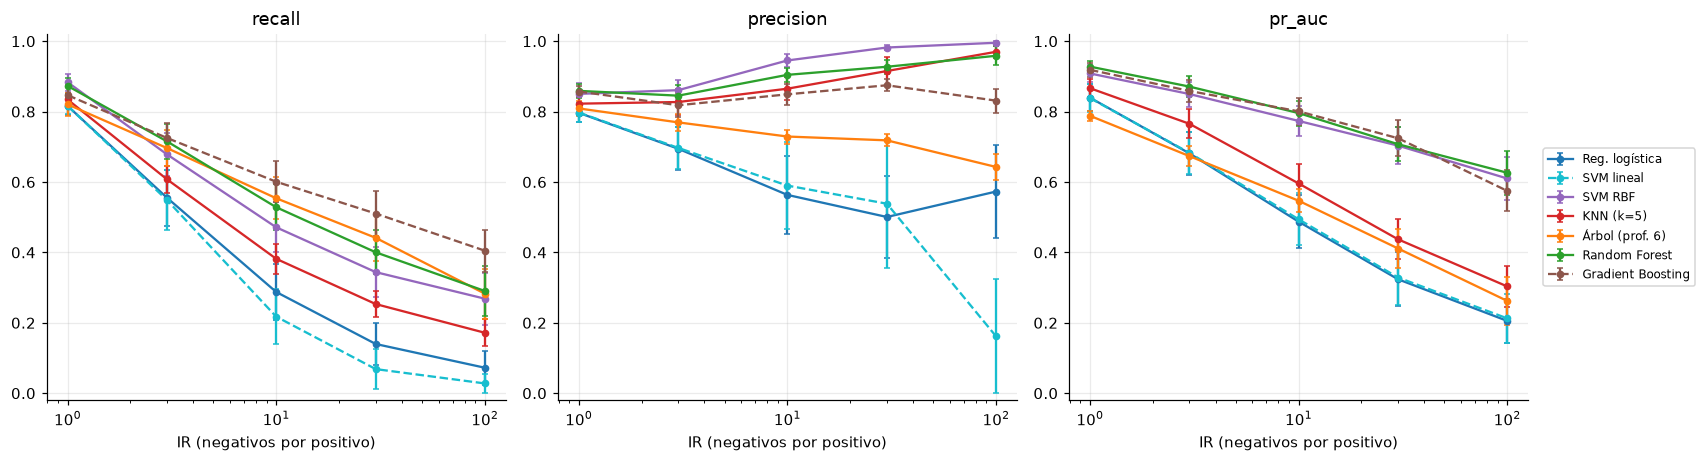

In [16]:
IRS = [1, 3, 10, 30, 100]
cfgB = [dict(modelo=n, IR=ir, n_pos=100, n_neg=100 * ir, prev_te=1 / (1 + ir)) for n in NOMBRES for ir in IRS]
dfB = correr(cfgB, reps=6)
graficar(dfB, 'IR', ['recall', 'precision', 'pr_auc'], logx=True, xlabel='IR (negativos por positivo)')

In [17]:
# Comparación directa a la misma prevalencia (1%): n fijo (A) vs positivos fijos (B)
comp = pd.DataFrame({'A: n=4000 (40 positivos)': dfA[dfA.prev == .01].groupby('modelo').pr_auc.mean(),
                     'B: 100 positivos (IR 1:100)': dfB[dfB.IR == 100].groupby('modelo').pr_auc.mean()}).loc[NOMBRES]
comp['Ganancia'] = comp.iloc[:, 1] - comp.iloc[:, 0]
comp.round(3)

,A: n=4000 (40 positivos),B: 100 positivos (IR 1:100),Ganancia
modelo,,,
Reg. logística,0.247,0.205,-0.041
SVM lineal,0.256,0.213,-0.043
SVM RBF,0.571,0.610,0.039
KNN (k=5),0.255,0.303,0.048
Árbol (prof. 6),0.179,0.262,0.083
Random Forest,0.479,0.626,0.147
Gradient Boosting,0.510,0.575,0.065


**Lectura:**

- Con 100 positivos fijos y 100 veces más negativos, **los modelos flexibles no se degradan igual que en la simulación A**: Random Forest, Gradient Boosting, árbol, KNN y SVM RBF obtienen una PR-AUC *mayor* con IR 1:100 y 100 positivos que con IR 1:100 y 40 positivos (columna "Ganancia" positiva). Los modelos lineales no mejoran (−0.04): no tienen capacidad para aprovechar más negativos.
- Aun así, al aumentar el IR con positivos fijos, **el recall con umbral 0.5 sí cae** en todos los modelos (de ≈0.85 a 0.03-0.40) y la PR-AUC baja: parte de la caída se debe a que con más negativos la tarea es intrínsecamente más difícil (más oportunidades de falsos positivos) y parte a que el umbral de 0.5 deja de ser razonable.
- **Conclusión:** el IR por sí solo no explica la degradación; el **número de positivos** es el recurso escaso. Comparar A y B a la misma prevalencia lo muestra con claridad. Antes de sofisticar el remuestreo, pregúntate si puedes conseguir más positivos.
- Esta lectura ya matiza una creencia habitual ("el desbalanceo siempre destruye el modelo"): los efectos son muy distintos por modelo y por cantidad de información.

<h3 style="color: #007ACC;">Simulación C. ¿Qué corrección funciona para cada modelo?</h3>

Con prevalencia del 2 % (100 positivos y 4 900 negativos para entrenar; prueba con 2 % de positivos), aplicamos cada corrección a cada modelo y medimos $F_1$, recall y precisión en el conjunto de prueba. KNN no admite pesos de clase, así que esa celda queda vacía. 8 réplicas por celda.

In [18]:
REMEDIOS = ['Ninguno', 'Pesos de clase', 'Sub-muestreo', 'Sobre-muestreo', 'SMOTE', 'Umbral (F1)']
cfgC = [dict(modelo=n, remedio=r, n_pos=100, n_neg=4900, prev_te=.02)
        for n in NOMBRES for r in REMEDIOS if not (r == 'Pesos de clase' and not SOPORTA_PESOS[n])]
dfC = correr(cfgC, reps=8)

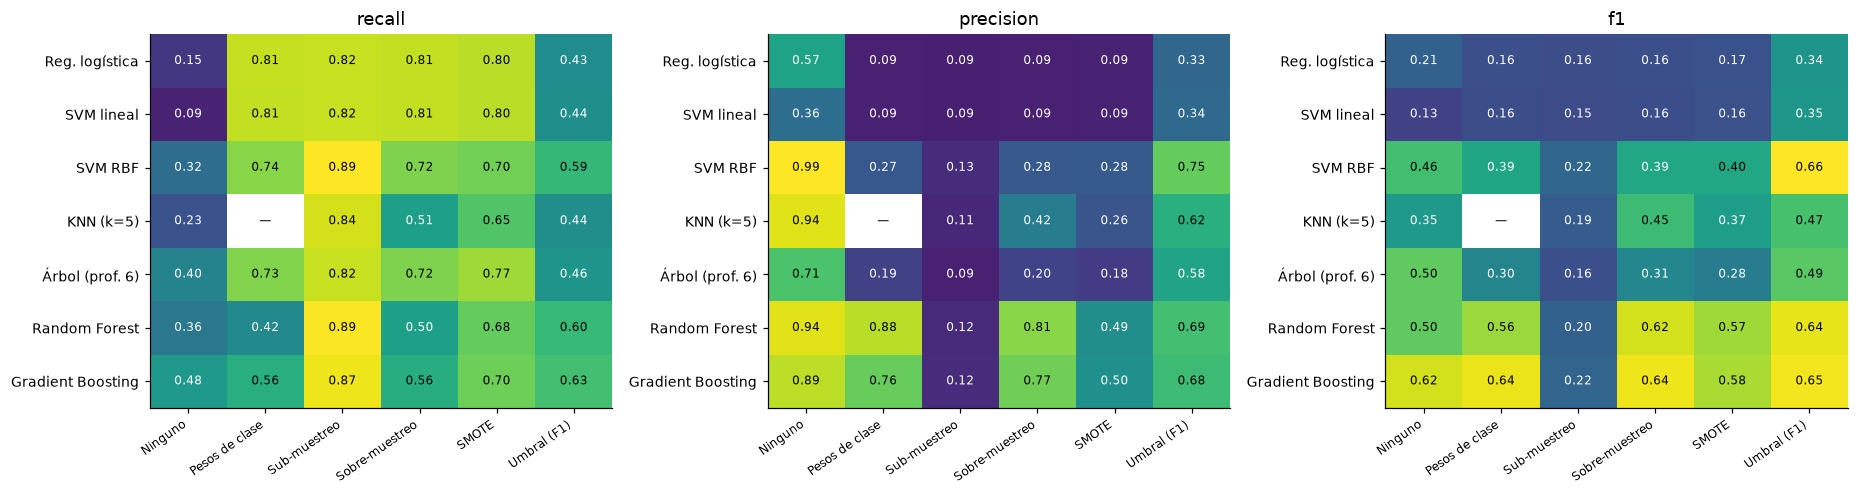

In [19]:
def mapa_calor(df, metrica, ax, cmap='viridis'):
    t = df.pivot_table(index='modelo', columns='remedio', values=metrica).reindex(index=NOMBRES, columns=REMEDIOS)
    im = ax.imshow(t.values, cmap=cmap, vmin=0, vmax=max(.01, np.nanmax(t.values)), aspect='auto')
    ax.set_xticks(range(len(REMEDIOS))); ax.set_xticklabels(REMEDIOS, rotation=35, ha='right', fontsize=8)
    ax.set_yticks(range(len(NOMBRES))); ax.set_yticklabels(NOMBRES, fontsize=9); ax.grid(False)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.values[i, j]
            ax.text(j, i, '—' if np.isnan(v) else f'{v:.2f}', ha='center', va='center', fontsize=8,
                    color='w' if (not np.isnan(v) and v < .6 * np.nanmax(t.values)) else 'k')
    ax.set_title(metrica)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, met in zip(axes, ['recall', 'precision', 'f1']):
    mapa_calor(dfC, met, ax)
plt.tight_layout(); plt.show()

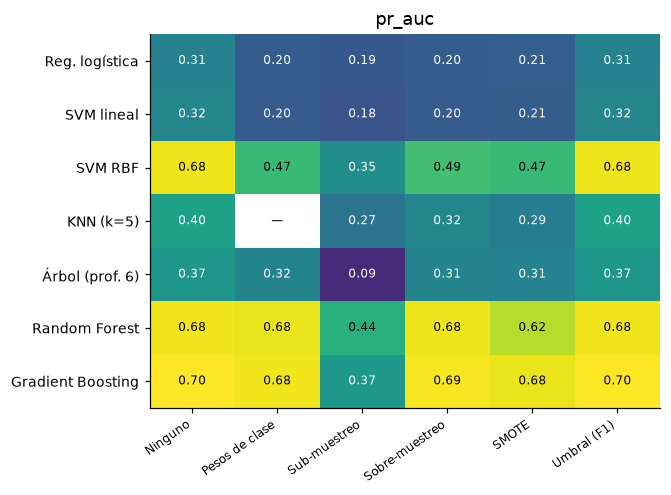

,F1 sin corrección,Mejor corrección,F1 con la mejor,Ganancia
modelo,,,,
Reg. logística,0.206,Umbral (F1),0.342,0.136
SVM lineal,0.129,Umbral (F1),0.348,0.220
SVM RBF,0.461,Umbral (F1),0.660,0.199
KNN (k=5),0.355,Umbral (F1),0.469,0.114
Árbol (prof. 6),0.498,Ninguno,0.498,0.000
Random Forest,0.500,Umbral (F1),0.636,0.136
Gradient Boosting,0.616,Umbral (F1),0.648,0.032


In [20]:
# PR-AUC por modelo y corrección (cambia solo si la técnica modifica el modelo aprendido, no si solo mueve el umbral)
fig, ax = plt.subplots(figsize=(6.2, 4.6)); mapa_calor(dfC, 'pr_auc', ax); plt.tight_layout(); plt.show()

# Mejor corrección (por F1) para cada modelo y su ganancia frente a no corregir
f1 = dfC.pivot_table(index='modelo', columns='remedio', values='f1').reindex(index=NOMBRES, columns=REMEDIOS)
resumen = pd.DataFrame({'F1 sin corrección': f1['Ninguno'], 'Mejor corrección': f1.idxmax(axis=1),
                        'F1 con la mejor': f1.max(axis=1)})
resumen['Ganancia'] = resumen['F1 con la mejor'] - resumen['F1 sin corrección']
resumen.round(3)

**Lectura:**

1. **El ajuste de umbral fue la mejor o casi la mejor corrección para 6 de los 7 modelos.** Mejora el $F_1$ en +0.11 a +0.22 en los modelos lineales, SVM RBF, KNN y Random Forest, sin modificar el entrenamiento. En el árbol no ayudó (ya decidía "positivo" con frecuencia razonable) y en Gradient Boosting la ganancia fue pequeña porque ya partía de un buen $F_1$.
2. **Pesos de clase y remuestreo suben el recall pero hunden la precisión**: en la regresión logística y el SVM lineal el recall pasa de ≈0.1 a ≈0.8 mientras la precisión cae de 0.4-0.6 a 0.09, y el $F_1$ *no mejora* (0.21 → 0.16). Es un intercambio de errores, no más información.
3. **El sub-muestreo es la técnica más agresiva**: máximo recall (0.82-0.89) y la peor precisión (0.09-0.13), y por lo tanto el peor $F_1$ en casi todos los modelos. Tira la mayor parte de los negativos, y con ellos la información sobre la frontera.
4. **En modelos de alta capacidad, el sobre-muestreo y los pesos son más inofensivos o útiles que en los lineales**: en Random Forest, `balanced_subsample` y el sobre-muestreo suben el $F_1$ (0.50 → 0.56-0.62) y en KNN el sobre-muestreo da $F_1$ 0.45 frente a 0.35 sin corrección. **SMOTE** no superó al sobre-muestreo simple en este problema (con 10 variables y clusters, interpolar entre vecinos no añadió valor).
5. **KNN no tiene pesos de clase** (celda vacía): sus opciones son remuestreo o umbral, y en esta simulación ambos dan resultados parecidos.
6. Un buen modelo base importa más que la corrección: **SVM RBF con umbral (F1 ≈0.66) y Gradient Boosting sin corrección (≈0.62) superan a la regresión logística con la mejor corrección (≈0.34)**.

<div style="border-left: 4px solid #007ACC; padding: 6px 12px; background: rgba(0,122,204,.08);">
<b>Receta práctica:</b> (1) elige el modelo por PR-AUC con validación estratificada; (2) ajusta el umbral para tu métrica o tu matriz de costos; (3) usa pesos o remuestreo solo si necesitas que el modelo aprenda una frontera distinta (modelos de alta capacidad) o si tu algoritmo no produce un puntaje utilizable; (4) si necesitas probabilidades, calibra al final.
</div>

<b>Límites de las simulaciones:</b> un solo generador de datos (clusters gaussianos), hiperparámetros fijos (sin búsqueda), 5-8 réplicas y una sola prevalencia en la simulación C. Los ejercicios 5 y 6 te piden variar algunas de estas condiciones.

<a id="ejercicios"></a>
<h2 style="color: #007ACC;">5. Ejercicios</h2>

Los ejercicios 1 a 4 son analíticos y los ejercicios 5 y 6 son **simulaciones**. Reutiliza las funciones definidas arriba (`evaluar`, `muestrear_escenario`, `construir`, `correr`, `corregir_prior`, `NOMBRES`). Las soluciones están en `Ejercicios/Soluciones/12_Desbalanceo_Clases_Solucion.ipynb`.

- [Ejercicio 1. La paradoja de la accuracy](#ejercicio-1)
- [Ejercicio 2. Fuga de datos con SMOTE](#ejercicio-2)
- [Ejercicio 3. Umbral con costos asimétricos](#ejercicio-3)
- [Ejercicio 4. Calibración tras balancear](#ejercicio-4)
- [Ejercicio 5. Simulación: separabilidad de las clases](#ejercicio-5)
- [Ejercicio 6. Simulación: curva de aprendizaje con prevalencia fija](#ejercicio-6)
- [Ejercicio 7. Integrador: guía de decisión por modelo](#ejercicio-7)

<a id="ejercicio-1"></a>
<h3 style="color: #007ACC;">Ejercicio 1. La paradoja de la accuracy</h3>


Con `load_breast_cancer`, define como **clase positiva los tumores malignos** (`target == 0`) y construye una versión desbalanceada conservando **todos** los benignos pero solo ~5 % de malignos respecto a los benignos (`n_malignos ≈ 0.05 * n_benignos`).

1. Haz una partición estratificada 70/30.
2. Entrena un `DummyClassifier(strategy='most_frequent')` y una regresión logística con escalado.
3. Compara *accuracy*, *balanced accuracy*, recall, precisión, $F_1$, MCC, ROC-AUC y PR-AUC con `evaluar`.
4. ¿Qué métrica engaña más? ¿Cuál es la línea base de la PR-AUC en este problema?

In [21]:
# Escribe tu código aquí

<a id="ejercicio-2"></a>
<h3 style="color: #007ACC;">Ejercicio 2. Fuga de datos con SMOTE</h3>


Con `muestrear_escenario(semilla=1, n_pos_tr=150, n_neg_tr=2850, prev_te=.05)`:

1. Estima el $F_1$ de **KNN (k=5)** y de un **árbol de profundidad 6** con validación cruzada estratificada repetida (5×3) de dos formas:
   - **(a) Incorrecta:** aplicar `SMOTE` a todo el conjunto de entrenamiento y luego hacer validación cruzada.
   - **(b) Correcta:** `imblearn.pipeline.Pipeline` con `SMOTE` dentro del pipeline.
2. Entrena cada modelo con SMOTE sobre todo el entrenamiento y mide el $F_1$ real en el conjunto de prueba (que el modelo nunca vio y conserva la prevalencia real).
3. ¿Cuál de las dos estimaciones se parece más al desempeño real? ¿Qué modelo se infla más y por qué?

In [22]:
# Escribe tu código aquí

<a id="ejercicio-3"></a>
<h3 style="color: #007ACC;">Ejercicio 3. Umbral con costos asimétricos</h3>


Un banco pierde 20 unidades por cada fraude no detectado ($c_{FN}=20$) y 1 unidad por cada falsa alarma ($c_{FP}=1$). Con `muestrear_escenario(semilla=2, n_pos_tr=300, n_neg_tr=9700, prev_te=.03)`:

1. Separa un conjunto de **validación** (30 %) del de entrenamiento.
2. Entrena una regresión logística (a) sin pesos y (b) con `class_weight='balanced'`.
3. Busca en la malla `t ∈ [0.01, 0.99]` el umbral que minimiza el costo total **en validación** para el modelo (a), y compáralo con el umbral teórico $t^*=c_{FP}/(c_{FP}+c_{FN})$.
4. Evalúa el costo total en el conjunto de **prueba** para: (a) con $t=0.5$, (a) con el umbral empírico, (a) con $t^*$ y (b) con $t=0.5$.
5. ¿Qué conclusión sacas sobre pesos vs. umbral para decisiones con costos?

In [23]:
# Escribe tu código aquí

<a id="ejercicio-4"></a>
<h3 style="color: #007ACC;">Ejercicio 4. Calibración tras balancear</h3>


Con `muestrear_escenario(semilla=3, n_pos_tr=200, n_neg_tr=9800, prev_te=.02)` entrena una regresión logística (1) sin corrección, (2) con `class_weight='balanced'` y (3) con `SMOTE`.

1. Calcula la probabilidad media predicha en prueba, el *Brier score* y la PR-AUC de cada una.
2. Aplica `corregir_prior` a (2) y (3) (en ambas la prevalencia aparente es 0.5) y recalcula.
3. Verifica que la PR-AUC **no cambia** al corregir (¿por qué?) y que el Brier score mejora.

In [24]:
# Escribe tu código aquí

<a id="ejercicio-5"></a>
<h3 style="color: #007ACC;">Ejercicio 5. Simulación: ¿la separabilidad de las clases cambia la susceptibilidad?</h3>


Hipótesis: cuando las clases están muy separadas, el desbalanceo duele menos; cuando se solapan, más.

Usando `correr` y `muestrear_escenario` (parámetro `sep`, que controla `class_sep`), simula con:

- `sep ∈ {0.5, 1.0, 2.0}`, `IR ∈ {1, 10, 100}`, 100 positivos de entrenamiento fijos,
- los modelos `Reg. logística`, `KNN (k=5)`, `Random Forest` y `Gradient Boosting`,
- 5 réplicas.

Grafica el **recall** y la **PR-AUC** frente al IR para cada `sep` (un panel por `sep`). Calcula también la **pérdida relativa de PR-AUC** entre IR 1 e IR 100 por modelo y `sep`. ¿Se confirma la hipótesis? ¿Qué modelo es más sensible cuando hay solapamiento?

*Pista:* añade la clave `sep` a cada diccionario de configuración.

In [25]:
# Escribe tu código aquí

<a id="ejercicio-6"></a>
<h3 style="color: #007ACC;">Ejercicio 6. Simulación: curva de aprendizaje con prevalencia fija</h3>


Con la prevalencia fija en 1 %, simula tamaños de entrenamiento `n ∈ {1 000, 3 000, 10 000, 30 000}` (de 10 a 300 positivos) para `Reg. logística`, `Random Forest` y `Gradient Boosting`, con y sin `Pesos de clase` (5 réplicas).

1. Grafica la **PR-AUC** frente a $n$ en escala logarítmica.
2. ¿A partir de cuántos positivos cada modelo "se estabiliza"?
3. ¿Los pesos de clase cambian el ranking (PR-AUC) o solo el recall con umbral 0.5? Contrástalo con el recall.
4. Conclusión: ¿qué es más rentable, una técnica de balanceo sofisticada o conseguir más positivos?

In [26]:
# Escribe tu código aquí

<a id="ejercicio-7"></a>
<h3 style="color: #007ACC;">Ejercicio 7. Integrador: guía de decisión por modelo</h3>

Con base en las simulaciones A, B y C y en tus propias simulaciones de los ejercicios 5 y 6, completa en **Markdown** una tabla con una fila por modelo (regresión logística, SVM, KNN, árbol, Random Forest, Gradient Boosting) y las columnas:

1. **Susceptibilidad** (baja/media/alta) y la evidencia que la respalda (cita números de tus simulaciones).
2. **Primera corrección que probarías** y por qué.
3. **Cuándo dejarías de insistir** con ese modelo y qué harías (más datos, otra métrica, otro modelo).

Cierra con un párrafo sobre qué métrica y qué protocolo de validación usarías en un problema real de fraude con prevalencia del 0.2 %.

*Escribe tu respuesta aquí.*